In [0]:
#import libraries
import findspark
import databricks.koalas as ks
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pyspark.pandas as ps
import pycaret.classification as pyc
from pyspark.sql import SparkSession
from pyspark.sql.functions import *



In [0]:

#Initiate Spark environment, create sesion with decided name, read the CSV as Spark DataFrame and then show it. 
findspark.init()
spark = SparkSession.builder.appName('Challenge_1').getOrCreate()
SparkDataFrame = spark.read.csv("/FileStore/tables/globalterrorismdb_0718dist.csv",inferSchema=True,header=True,sep=",")
SparkDataFrame.show()


+------------+-----+------+----+----------+--------+----------+-------+------------------+------+--------------------+-----------+-------------+----------+-----------+-----------+--------+--------------------+--------------------+-----+-----+-----+---------+-----------+--------------------+--------+-------+-------+-----------+--------------------+-----------+---------------+-----------+---------------+---------+--------------------+------------+--------------------+--------------------+--------------------+-------+------------------+---------+-------------+------------+----------------+-----+-------+-------+-----------+---------+-------------+------------+----------------+-----+-------+-------+-----------+--------------------+--------+------+---------+------+---------+--------------------+-----------+-----------+-----------+----------+------+--------+-------+---------+-------------+------+----------+--------------+------+----------+--------------+---------+---------+-------------+-----

In [0]:
# Once we have it into a Spark DataFrame we can convert it to Koalas DataFrame
koalas_dataframe = ks.DataFrame(SparkDataFrame)
koalas_dataframe.head()

,eventid,iyear,imonth,iday,approxdate,extended,resolution,country,country_txt,region,region_txt,provstate,city,latitude,longitude,specificity,vicinity,location,summary,crit1,crit2,crit3,doubtterr,alternative,alternative_txt,multiple,success,suicide,attacktype1,attacktype1_txt,attacktype2,attacktype2_txt,attacktype3,attacktype3_txt,targtype1,targtype1_txt,targsubtype1,targsubtype1_txt,corp1,target1,natlty1,natlty1_txt,targtype2,targtype2_txt,targsubtype2,targsubtype2_txt,corp2,target2,natlty2,natlty2_txt,targtype3,targtype3_txt,targsubtype3,targsubtype3_txt,corp3,target3,natlty3,natlty3_txt,gname,gsubname,gname2,gsubname2,gname3,gsubname3,motive,guncertain1,guncertain2,guncertain3,individual,nperps,nperpcap,claimed,claimmode,claimmode_txt,claim2,claimmode2,claimmode2_txt,claim3,claimmode3,claimmode3_txt,compclaim,weaptype1,weaptype1_txt,weapsubtype1,weapsubtype1_txt,weaptype2,weaptype2_txt,weapsubtype2,weapsubtype2_txt,weaptype3,weaptype3_txt,weapsubtype3,weapsubtype3_txt,weaptype4,weaptype4_txt,weapsubtype4,weapsubtype4_txt,weapdetail,nkill,nkillus,nkillter,nwound,nwoundus,nwoundte,property,propextent,propextent_txt,propvalue,propcomment,ishostkid,nhostkid,nhostkidus,nhours,ndays,divert,kidhijcountry,ransom,ransomamt,ransomamtus,ransompaid,ransompaidus,ransomnote,hostkidoutcome,hostkidoutcome_txt,nreleased,addnotes,scite1,scite2,scite3,dbsource,INT_LOG,INT_IDEO,INT_MISC,INT_ANY,related
0,197000000001,1970,7,2,None,0,None,58,Dominican Republic,2,Central America & Caribbean,None,Santo Domingo,18.456792,-69.951164,1,0,None,None,1,1,1,0,None,None,0,1,0,1,Assassination,None,None,None,None,14,Private Citizens & Property,68,Named Civilian,None,Julio Guzman,58,Dominican Republic,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,MANO-D,None,None,None,None,None,None,0,None,None,0,None,None,None,None,None,None,None,None,None,None,None,None,13,Unknown,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,1,None,None,0,None,None,0,None,None,None,None,0,None,None,None,None,None,None,0,None,None,None,None,None,None,None,None,None,None,None,None,PGIS,0,0,0,0,None
1,197000000002,1970,0,0,None,0,None,130,Mexico,1,North America,Federal,Mexico city,19.371887,-99.086624,1,0,None,None,1,1,1,0,None,None,0,1,0,6,Hostage Taking (Kidnapping),None,None,None,None,7,Government (Diplomatic),45,"Diplomatic Personnel (outside of embassy, cons...",Belgian Ambassador Daughter,"Nadine Chaval, daughter",21,Belgium,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,23rd of September Communist League,None,None,None,None,None,None,0,None,None,0,7,None,None,None,None,None,None,None,None,None,None,None,13,Unknown,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,0,None,None,0,None,None,0,None,None,None,None,1,1,0,None,None,None,Mexico,1,800000,None,None,None,None,None,None,None,None,None,None,None,PGIS,0,1,1,1,None
2,197001000001,1970,1,0,None,0,None,160,Philippines,5,Southeast Asia,Tarlac,Unknown,15.478598,120.599741,4,0,None,None,1,1,1,0,None,None,0,1,0,1,Assassination,None,None,None,None,10,Journalists & Media,54,Radio Journalist/Staff/Facility,Voice of America,Employee,217,United States,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,Unknown,None,None,None,None,None,None,0,None,None,0,None,None,None,None,None,None,None,None,None,None,None,None,13,Unknown,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,1,None,None,0,None,None,0,None,None,None,None,0,None,None,None,None,None,None,0,None,None,None,None,None,None,None,None,None,None,None,None,PGIS,-9,-9,1,1,None
3,197001000002,1970,1,0,None,0,None,78,Greece,8,Western Europe,Attica,Athens,37.997490,23.762728,1,0,None,None,1,1,1,0,None,None,0,1,0,3,Bombing/Explosion,None,None,None,None,7,Government (Diplomatic),46,Embassy/Consulate,None,U.S. Embassy,217,United States,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,Unknown,None

In [0]:
#Another way to import the data into koalas DataFrame by skipping the spark session. 
koalas_dataframe = ks.read_csv("/FileStore/tables/globalterrorismdb_0718dist.csv")
koalas_dataframe.head()

,eventid,iyear,imonth,iday,approxdate,extended,resolution,country,country_txt,region,region_txt,provstate,city,latitude,longitude,specificity,vicinity,location,summary,crit1,crit2,crit3,doubtterr,alternative,alternative_txt,multiple,success,suicide,attacktype1,attacktype1_txt,attacktype2,attacktype2_txt,attacktype3,attacktype3_txt,targtype1,targtype1_txt,targsubtype1,targsubtype1_txt,corp1,target1,natlty1,natlty1_txt,targtype2,targtype2_txt,targsubtype2,targsubtype2_txt,corp2,target2,natlty2,natlty2_txt,targtype3,targtype3_txt,targsubtype3,targsubtype3_txt,corp3,target3,natlty3,natlty3_txt,gname,gsubname,gname2,gsubname2,gname3,gsubname3,motive,guncertain1,guncertain2,guncertain3,individual,nperps,nperpcap,claimed,claimmode,claimmode_txt,claim2,claimmode2,claimmode2_txt,claim3,claimmode3,claimmode3_txt,compclaim,weaptype1,weaptype1_txt,weapsubtype1,weapsubtype1_txt,weaptype2,weaptype2_txt,weapsubtype2,weapsubtype2_txt,weaptype3,weaptype3_txt,weapsubtype3,weapsubtype3_txt,weaptype4,weaptype4_txt,weapsubtype4,weapsubtype4_txt,weapdetail,nkill,nkillus,nkillter,nwound,nwoundus,nwoundte,property,propextent,propextent_txt,propvalue,propcomment,ishostkid,nhostkid,nhostkidus,nhours,ndays,divert,kidhijcountry,ransom,ransomamt,ransomamtus,ransompaid,ransompaidus,ransomnote,hostkidoutcome,hostkidoutcome_txt,nreleased,addnotes,scite1,scite2,scite3,dbsource,INT_LOG,INT_IDEO,INT_MISC,INT_ANY,related
0,197000000001,1970,7,2,None,0,None,58,Dominican Republic,2,Central America & Caribbean,None,Santo Domingo,18.456792,-69.951164,1,0,None,None,1,1,1,0,None,None,0,1,0,1,Assassination,None,None,None,None,14,Private Citizens & Property,68,Named Civilian,None,Julio Guzman,58,Dominican Republic,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,MANO-D,None,None,None,None,None,None,0,None,None,0,None,None,None,None,None,None,None,None,None,None,None,None,13,Unknown,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,1,None,None,0,None,None,0,None,None,None,None,0,None,None,None,None,None,None,0,None,None,None,None,None,None,None,None,None,None,None,None,PGIS,0,0,0,0,None
1,197000000002,1970,0,0,None,0,None,130,Mexico,1,North America,Federal,Mexico city,19.371887,-99.086624,1,0,None,None,1,1,1,0,None,None,0,1,0,6,Hostage Taking (Kidnapping),None,None,None,None,7,Government (Diplomatic),45,"Diplomatic Personnel (outside of embassy, cons...",Belgian Ambassador Daughter,"Nadine Chaval, daughter",21,Belgium,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,23rd of September Communist League,None,None,None,None,None,None,0,None,None,0,7,None,None,None,None,None,None,None,None,None,None,None,13,Unknown,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,0,None,None,0,None,None,0,None,None,None,None,1,1,0,None,None,None,Mexico,1,800000,None,None,None,None,None,None,None,None,None,None,None,PGIS,0,1,1,1,None
2,197001000001,1970,1,0,None,0,None,160,Philippines,5,Southeast Asia,Tarlac,Unknown,15.478598,120.599741,4,0,None,None,1,1,1,0,None,None,0,1,0,1,Assassination,None,None,None,None,10,Journalists & Media,54,Radio Journalist/Staff/Facility,Voice of America,Employee,217,United States,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,Unknown,None,None,None,None,None,None,0,None,None,0,None,None,None,None,None,None,None,None,None,None,None,None,13,Unknown,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,1,None,None,0,None,None,0,None,None,None,None,0,None,None,None,None,None,None,0,None,None,None,None,None,None,None,None,None,None,None,None,PGIS,-9,-9,1,1,None
3,197001000002,1970,1,0,None,0,None,78,Greece,8,Western Europe,Attica,Athens,37.997490,23.762728,1,0,None,None,1,1,1,0,None,None,0,1,0,3,Bombing/Explosion,None,None,None,None,7,Government (Diplomatic),46,Embassy/Consulate,None,U.S. Embassy,217,United States,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,Unknown,None

In [0]:
koalas_dataframe.dtypes

Out[5]: eventid        int64
iyear          int32
imonth         int32
iday           int32
approxdate    object
               ...  
INT_LOG       object
INT_IDEO      object
INT_MISC      object
INT_ANY       object
related       object
Length: 135, dtype: object

In [0]:
# Group by 'country_txt', count and sort descending
country_counts = koalas_dataframe.groupby('country_txt')['country_txt'].count().sort_values(ascending = False)
country_counts

Out[6]: country_txt
Iraq                                24636
Pakistan                            14368
Afghanistan                         12731
India                               11960
Colombia                             8306
Philippines                          6908
Peru                                 6096
El Salvador                          5320
United Kingdom                       5235
Turkey                               4292
Somalia                              4142
Nigeria                              3907
Thailand                             3849
Yemen                                3347
Spain                                3249
Sri Lanka                            3022
United States                        2836
Algeria                              2743
France                               2693
Egypt                                2479
Lebanon                              2478
Chile                                2365
Libya                                2249
West Bank and 

Out[7]: <AxesSubplot:title={'center':' Top 9 countries with the highest number of terrorist attacks'}, xlabel='country_txt'>

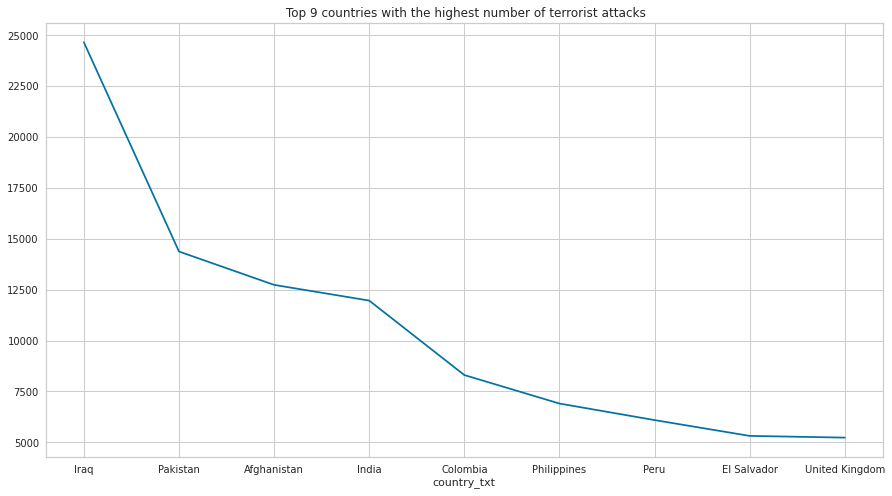

In [0]:
# Top 9 countries with the highest number of terrorist attacks
top9_countries = country_counts.head(9)

# matplotlib Graph
top9_countries.plot(backend="matplotlib", title=" Top 9 countries with the highest number of terrorist attacks",figsize=(15,8))


In [0]:
# Top 15 countries with the highest number of terrorist attacks
top15_countries = country_counts.head(15)
top15_countries.plot(backend = "plotly" , title= 'Highest number of terrorist attacks per country')


In [0]:
#Bar Graph
top15_countries.plot.bar()

In [0]:
#Replace large text into a word to fit on the table
koalas_dataframe = koalas_dataframe.replace({'weaptype1_txt': 'Vehicle (not to include vehicle-borne explosives, i.e., car or truck bombs)'}, 'Vehicle')

In [0]:
# Group by type of weapon, count, then sort descending and show only first 8 results
weapon_type = koalas_dataframe.groupby('weaptype1_txt')['weaptype1_txt'].count().sort_values(ascending = False).head(8)
weapon_type


Out[11]: weaptype1_txt
Explosives            92085
Firearms              58346
Unknown               15118
Incendiary            11000
Melee                  3619
Chemical                318
Vehicle                 132
Sabotage Equipment      131
Name: weaptype1_txt, dtype: int64

Out[12]: <AxesSubplot:title={'center':'Kinds of Weapons'}, xlabel='weaptype1_txt'>

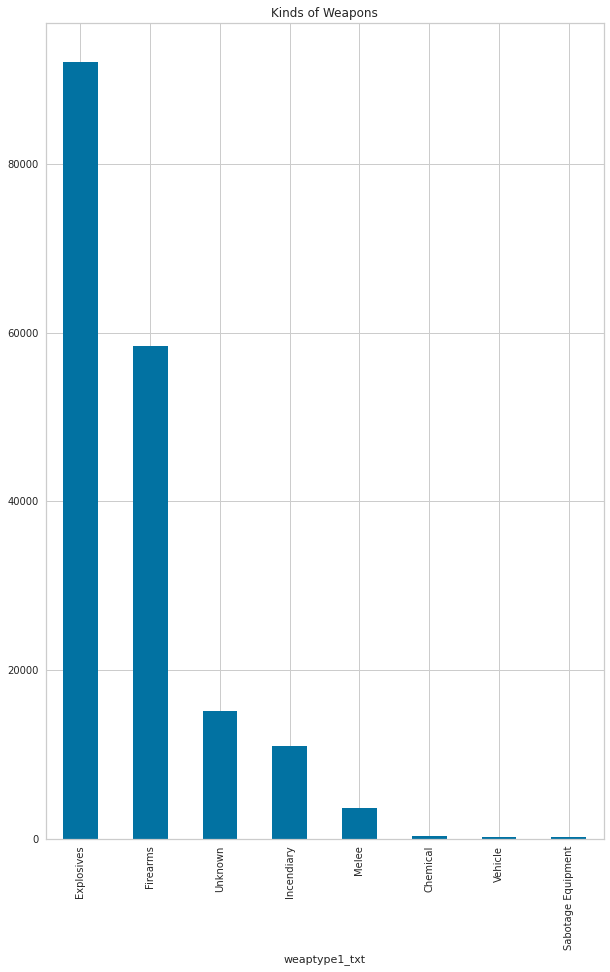

In [0]:
#Graph weapon types
weapon_type.plot.bar(backend='matplotlib',title='Kinds of Weapons',figsize=(10,15))

In [0]:
#Graph weapon types different format 
weapon_type.plot.barh(title='Kinds of weapons')


In [0]:
# Group by all the cities, count and sort descending
city = koalas_dataframe.groupby('city')['city'].count().sort_values(ascending = False)
city

Out[14]: city
Unknown                           9775
Baghdad                           7589
Karachi                           2652
Lima                              2359
Mosul                             2265
Belfast                           2171
Santiago                          1621
Mogadishu                         1581
San Salvador                      1558
Istanbul                          1048
Athens                            1019
Bogota                             984
Kirkuk                             925
Beirut                             918
Medellin                           848
Benghazi                           840
Peshawar                           819
Quetta                             803
Guatemala City                     755
Baqubah                            745
Kabul                              738
Srinagar                           658
Jerusalem                          636
Paris                              612
Fallujah                           582
Tripoli    

In [0]:
# Filter the information in USA and show first 5 lines
USA_Data = koalas_dataframe[koalas_dataframe.country_txt == 'United States']
USA_Data.head(5) 

,eventid,iyear,imonth,iday,approxdate,extended,resolution,country,country_txt,region,region_txt,provstate,city,latitude,longitude,specificity,vicinity,location,summary,crit1,crit2,crit3,doubtterr,alternative,alternative_txt,multiple,success,suicide,attacktype1,attacktype1_txt,attacktype2,attacktype2_txt,attacktype3,attacktype3_txt,targtype1,targtype1_txt,targsubtype1,targsubtype1_txt,corp1,target1,natlty1,natlty1_txt,targtype2,targtype2_txt,targsubtype2,targsubtype2_txt,corp2,target2,natlty2,natlty2_txt,targtype3,targtype3_txt,targsubtype3,targsubtype3_txt,corp3,target3,natlty3,natlty3_txt,gname,gsubname,gname2,gsubname2,gname3,gsubname3,motive,guncertain1,guncertain2,guncertain3,individual,nperps,nperpcap,claimed,claimmode,claimmode_txt,claim2,claimmode2,claimmode2_txt,claim3,claimmode3,claimmode3_txt,compclaim,weaptype1,weaptype1_txt,weapsubtype1,weapsubtype1_txt,weaptype2,weaptype2_txt,weapsubtype2,weapsubtype2_txt,weaptype3,weaptype3_txt,weapsubtype3,weapsubtype3_txt,weaptype4,weaptype4_txt,weapsubtype4,weapsubtype4_txt,weapdetail,nkill,nkillus,nkillter,nwound,nwoundus,nwoundte,property,propextent,propextent_txt,propvalue,propcomment,ishostkid,nhostkid,nhostkidus,nhours,ndays,divert,kidhijcountry,ransom,ransomamt,ransomamtus,ransompaid,ransompaidus,ransomnote,hostkidoutcome,hostkidoutcome_txt,nreleased,addnotes,scite1,scite2,scite3,dbsource,INT_LOG,INT_IDEO,INT_MISC,INT_ANY,related
5,197001010002,1970,1,1,None,0,None,217,United States,1,North America,Illinois,Cairo,37.005105,-89.176269,1,0,None,1/1/1970: Unknown African American assailants ...,1,1,1,0,None,None,0,1,0,2,Armed Assault,None,None,None,None,3,Police,22,"Police Building (headquarters, station, school)",Cairo Police Department,Cairo Police Headquarters,217,United States,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,Black Nationalists,None,None,None,None,None,To protest the Cairo Illinois Police Deparment,0,None,None,0,-99,-99,0,None,None,None,None,None,None,None,None,None,5,Firearms,5,Unknown Gun Type,None,None,None,None,None,None,None,None,None,None,None,None,Several gunshots were fired.,0,0,0,0,0,0,1,3,Minor (likely < $1 million),None,None,0,None,None,None,None,None,None,0,None,None,None,None,None,None,None,None,"The Cairo Chief of Police, William Petersen, r...","""""""Police Chief Quits",""""" Washington Post",January 2,"1970.""","""""""Cairo Police Chief Quits; Decries Local 'Mi...",""""" Afro-American",January 10,"1970.""","""Christopher Hewitt, """"Political Violence and ..."
7,197001020002,1970,1,2,None,0,None,217,United States,1,North America,California,Oakland,37.791927,-122.225906,1,0,Edes Substation,1/2/1970: Unknown perpetrators detonated explo...,1,1,1,1,2,Other Crime Type,0,1,0,3,Bombing/Explosion,None,None,None,None,21,Utilities,107,Electricity,Pacific Gas & Electric Company,Edes Substation,217,United States,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,Unknown,None,None,None,None,None,None,0,None,None,0,-99,-99,0,None,None,None,None,None,None,None,None,None,6,Explosives,16,Unknown Explosive Type,None,None,None,None,None,None,None,None,None,None,None,None,None,0,0,0,0,0,0,1,3,Minor (likely < $1 million),22500,Three transformers were damaged.,0,None,None,None,None,None,None,0,None,None,None,None,None,None,None,None,"Damages were estimated to be between $20,000-$...","""Committee on Government Operations United Sta...",Civil,and Criminal Disorders,""""" U.S. Government Printing Office",August 6,"1970.""","""Christopher Hewitt, """"Political Violence and ...",""""" Praeger Security International","2005."""
8,197001020003,1970,1,2,None,0,None,217,United States,1,North America,Wisconsin,Madison,43.076592,-89.412488,1,0,None,"1/2/1970: Karl Armstrong, a member of the New ...",1,1,1,0,None,None,0,1,0,7,Facility/Infrastructure Attack,None,None,None,None,4,Military,28,Military Recruiting Station/Academy,R.O.T.C.,"R.O.T.C. offices at University of Wisconsin, M...",217,United States,None,Non

In [0]:
# Get the information from all the cities in USA
cities_in_USA = USA_Data['city']
cities_in_USA


Out[18]: 5                       Cairo
7                     Oakland
8                     Madison
9                     Madison
10                    Baraboo
11                     Denver
13                    Detroit
14                Rio Piedras
17              New York City
18                 Rio Grande
19                    Seattle
20                  Champaign
22                    Seattle
23                    Seattle
24                Jersey City
28           South Sioux City
29                 West Point
30              New York City
31                 West Point
32              New York City
33                    Norwalk
35                    Seattle
36           South Sioux City
37           South Sioux City
38               Coral Gables
40                     Denver
41                   Portland
42                      Cairo
43              New York City
44              New York City
45              New York City
46                      Akron
47                     Denver
4

In [0]:
# Count and sort all the cities in USA
cities_in_USA = cities_in_USA.groupby([cities_in_USA]).count().sort_values(ascending=False)
cities_in_USA 

Out[19]: city
New York City            460
San Juan                 116
Los Angeles              109
San Francisco             98
Washington                85
Miami                     85
Chicago                   57
Seattle                   39
Berkeley                  33
Denver                    23
San Diego                 22
Portland                  22
Oakland                   20
Kansas City               19
San Jose                  18
Houston                   18
Boston                    18
Rio Piedras               17
Sacramento                16
Detroit                   15
Unknown                   15
Albuquerque               15
Phoenix                   14
Fresno                    13
Cairo                     12
Carolina                  12
Columbus                  12
Atlanta                   12
Arlington                 12
Eugene                    12
Palo Alto                 11
Cambridge                 11
Baton Rouge               11
Caguas                    10


In [0]:
# Bar Graph for 10 most dangerous places (cities) according to terrorist attacks in USA
#cities_in_USA = cities_in_USA.head(10)
BargraphTop10Cities  = cities_in_USA.head(10).plot.bar(title='Top Cities with terrorists attacks in the USA')
BargraphTop10Cities


In [0]:
# Get the information from all states in USA
states_in_USA = USA_Data ['provstate']
states_in_USA

Out[22]: 5                   Illinois
7                 California
8                  Wisconsin
9                  Wisconsin
10                 Wisconsin
11                  Colorado
13                  Michigan
14               Puerto Rico
17                  New York
18               Puerto Rico
19                Washington
20                  Illinois
22                Washington
23                Washington
24                New Jersey
28                  Nebraska
29               Mississippi
30                  New York
31               Mississippi
32                  New York
33                      Ohio
35                Washington
36                  Nebraska
37                  Nebraska
38                   Florida
40                  Colorado
41                    Oregon
42                  Illinois
43                  New York
44                  New York
45                  New York
46                      Ohio
47                  Colorado
48                Washington
49   

In [0]:
#  Count and sort all the states in the USA
states_in_USA = states_in_USA.groupby([states_in_USA]).count().sort_values(ascending=False)
states_in_USA

Out[23]: provstate
California              595
New York                515
Puerto Rico             248
Florida                 158
Illinois                112
Washington              101
District of Columbia     83
Oregon                   67
Texas                    63
Massachusetts            57
Ohio                     51
New Jersey               47
Michigan                 45
Colorado                 45
Virginia                 42
Missouri                 39
Wisconsin                37
Maryland                 35
North Carolina           34
Arizona                  34
Pennsylvania             33
Georgia                  29
Minnesota                25
Nebraska                 24
New Mexico               24
Iowa                     24
Tennessee                24
Louisiana                22
Indiana                  22
Utah                     20
Nevada                   18
Connecticut              17
Alabama                  16
Oklahoma                 15
Kansas                   14
I

In [0]:
# Bar Graph for 7 most dangerous places (states) according to terrorist attacks in USA
states_in_USA_top7 = states_in_USA.head(7)
BargraphTop7States = states_in_USA_top7.plot.barh(title='Top States with terrorists attacks in the USA')
BargraphTop7States 

In [0]:
#Attack types in Iraq

Iraq_Data = koalas_dataframe[koalas_dataframe.country_txt == 'Iraq']
Iraq_Attack_Type = Iraq_Data['attacktype1_txt']
Iraq_Attack_Type 



Out[26]: 2854                          Hijacking
4385                  Bombing/Explosion
4393        Hostage Taking (Kidnapping)
4402                      Assassination
8688                      Assassination
9688                      Armed Assault
10109                         Hijacking
10534                 Bombing/Explosion
10588                 Bombing/Explosion
11252                 Bombing/Explosion
11341                     Assassination
12208                     Assassination
12578       Hostage Taking (Kidnapping)
13522       Hostage Taking (Kidnapping)
13680       Hostage Taking (Kidnapping)
15236                 Bombing/Explosion
15846                     Armed Assault
16438       Hostage Taking (Kidnapping)
16723                 Bombing/Explosion
17596                 Bombing/Explosion
18229                 Bombing/Explosion
18230                 Bombing/Explosion
18470                 Bombing/Explosion
21450                 Bombing/Explosion
22288       Hostage Taking (Kid

In [0]:
#  Count and sort 
Iraq_Attack_Type = Iraq_Attack_Type.groupby([Iraq_Attack_Type]).count().sort_values(ascending=False)


#  Graph the types of attack in Iraq
Iraq_Attack_Type_top5 = Iraq_Attack_Type.head(5)
IraqGraph = Iraq_Attack_Type_top5.plot.bar(title='Top Types of Attack in Iraq')
IraqGraph 


In [0]:
spark.stop()